# Task 5: Account anomaly detection

รายงาน EDA จากข้อมูลในเครื่อง วันที่ 2 พฤศจิกายน 2026 ไม่มีการฝึกโมเดลใน notebook นี้ ค่าที่เขียนใน Markdown อิง snapshot ที่ตรวจครั้งนี้ หากเปลี่ยนข้อมูลให้สร้างรายงานใหม่และรันทุก cell อีกครั้ง

## 1. Task Overview

ค้นหาบัญชีที่มีพฤติกรรมเปลี่ยนไป เพื่อจัดลำดับการตรวจสอบความปลอดภัย

Target: `is_anomaly`. 0=ปกติ, 1=น่าสงสัย แต่ไม่มี label ให้ตรวจ

ไม่พบ metric ทางการในไฟล์ที่ได้รับ หากมี label ให้ตรวจ PR-AUC/F1 และ precision ตามงบตรวจสอบ ยังรายงานคะแนนเหล่านี้ไม่ได้

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / 'sample_submission.csv').exists())
sys.path.insert(0, str(ROOT))
from shared.eda_utils import (
    TASKS, load_task, quality_table, outlier_table, bounds_table,
    association, strongest_pairs, period_changes, image_inventory, setup_plot,
)
setup_plot()

train, test, target, base = load_task(ROOT, 5)
frame = train if train is not None else test
features = frame.drop(columns=['player_id', target], errors='ignore')

## 2. Dataset Overview

| กลุ่ม | ความหมายตาม data card |
|---|---|
| login/location/device | จำนวน login พิกัด การเปลี่ยนที่อยู่ อุปกรณ์ และ IP entropy |
| session/activity | เวลา login ระยะ session pattern consistency และ activity |
| performance | skill rating/trajectory, KDA, accuracy, reaction time และ stability |
| purchase/social | ความถี่และยอดซื้อ refund transfer friend communication และ guild |
| account/flags | อายุบัญชี stability password VPN เวลา login ผิดปกติและ mass sale |

Suffix `_1` ถึง `_4` เป็น 4 ช่วงเวลาต่อเนื่อง ไม่ทราบความยาวแต่ละช่วง และแต่ละแถวคือบัญชีหนึ่งบัญชี

In [2]:
overview = pd.DataFrame([
    {'split': name, 'rows': len(data), 'columns': data.shape[1],
     'target_available': int(data[target].notna().sum()) if target in data else 0}
    for name, data in [('train', train), ('test', test)] if data is not None
])
display(overview)
display(features.dtypes.astype(str).value_counts().rename('feature_count').to_frame())
with pd.option_context('display.max_rows', None):
    display(features.dtypes.astype(str).to_frame('dtype'))
display(frame.drop(columns='player_id').head(3))

,split,rows,columns,target_available
0,test,25889,123,0


,feature_count
float64,122


,dtype
login_count_1,float64
login_count_2,float64
login_count_3,float64
login_count_4,float64
login_lat_1,float64
login_lon_1,float64
login_lat_2,float64
login_lon_2,float64
login_lat_3,float64
login_lon_3,float64


,login_count_1,login_count_2,login_count_3,login_count_4,login_lat_1,login_lon_1,...,account_age_days,behavior_stability,password_changed,vpn_usage,suspicious_login_time,mass_item_sale
0,90.3113,90.5476,85.6962,85.4671,NaN,-73.2759,...,363.8724,0.7266,0.0000,0.0000,0.0000,0.0000
1,92.5222,67.9065,113.6784,98.3214,-40.2479,-126.3804,...,"1,218.2369",0.7741,0.0000,0.0000,1.0000,0.0000
2,26.2085,24.8372,28.1424,31.5348,9.0238,-137.1293,...,502.0368,0.8514,0.0000,0.0000,0.0000,0.0000


**Findings & Interpretation**

**Findings:** ไม่มีไฟล์ train; test มี 25,889 แถว, feature 122 ตัว และ label ที่ใช้ได้ 0 แถว

**Interpretation:** ต้องแยกความครบของ feature ออกจากความครบของ label

**ML Implications:** ไม่เติม target ที่หายและไม่ใช้ player_id เป็น predictor

**Recommended Action:** ตรวจ missing และขอบเขตข้อมูลก่อนเลือก preprocessing

## 3. Data Quality Analysis

Duplicate IDs: 0
Duplicate feature rows: 0


,dtype,missing,missing_pct,unique
ip_hash_entropy_4,float64,1328,5.1296,24561
session_duration_std_4,float64,1324,5.1141,24565
friend_adds_1,float64,1319,5.0948,23376
kda_mean_4,float64,1316,5.0832,24573
login_count_4,float64,1314,5.0755,24575
activity_level_4,float64,1314,5.0755,24575
friend_adds_3,float64,1313,5.0717,23375
accuracy_std_3,float64,1305,5.0408,24584
location_changes_2,float64,1305,5.0408,24584
kda_std_3,float64,1302,5.0292,24587


,feature,expected_min,expected_max,outside_range
0,login_count_1,0,inf,0
1,login_count_2,0,inf,0
2,login_count_3,0,inf,0
3,login_count_4,0,inf,0
4,login_lat_1,-90,90.0000,0
...,...,...,...,...
55,guild_changes_4,0,inf,0
56,password_changed,0,1.0000,0
57,vpn_usage,0,1.0000,0
58,suspicious_login_time,0,1.0000,0


,iqr_outliers,observed,outlier_pct
vpn_usage,3861,24594,15.6990
password_changed,1542,24596,6.2693
suspicious_login_time,1215,24666,4.9258
mass_item_sale,673,24610,2.7347
skill_trajectory_1,639,24718,2.5852
skill_trajectory_4,506,24617,2.0555
skill_trajectory_2,495,24604,2.0119
location_changes_4,479,24604,1.9468


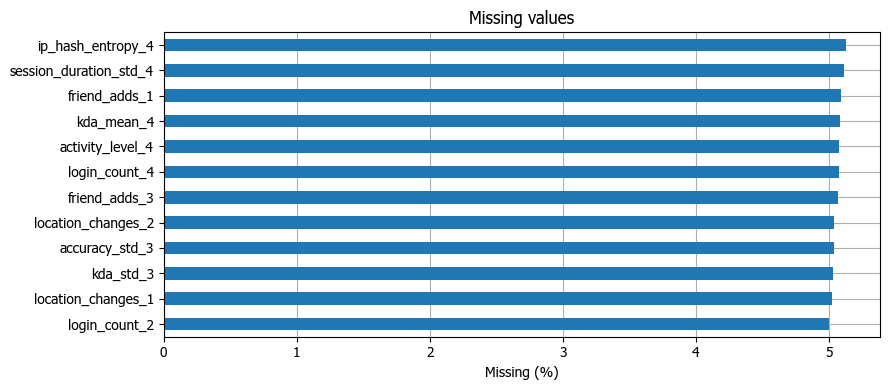

In [3]:
quality = quality_table(features)
display(quality.head(12))
print('Duplicate IDs:', int(frame.player_id.duplicated().sum()))
print('Duplicate feature rows:', int(features.duplicated().sum()))
if train is not None:
    print('Train/test ID overlap:', len(set(train.player_id) & set(test.player_id)))
    print('Missing target:', int(train[target].isna().sum()))
display(bounds_table(frame, 5))
display(outlier_table(features).head(8))
quality.missing_pct.head(12).sort_values().plot.barh(xlabel='Missing (%)', title='Missing values')
plt.tight_layout()
plt.show()

**Findings & Interpretation**

**Findings:** Feature missing เฉลี่ย 4.87%; สูงสุด `ip_hash_entropy_4` 5.13%; duplicate feature rows 0; พบค่าที่อยู่นอกช่วงตรวจทั้งหมด 14,073 จุด (นับระดับ cell); feature ที่มี IQR outlier สูงสุดคือ `vpn_usage` 15.70%

**Interpretation:** ค่าหลุด IQR เป็น outlier เชิงสถิติ ไม่ยืนยันว่าเป็นข้อมูลผิด ช่วงที่ตรวจมาจากความหมายใน data card และอาจสะท้อนนิยามหรือข้อมูลสังเคราะห์ที่ต่างออกไป

**ML Implications:** ใช้โมเดลรองรับ missing หรือ fit imputer เฉพาะ training fold; ยังไม่ clip ทั้งชุด

**Recommended Action:** ตรวจ feature ที่อยู่นอกช่วงกับนิยามต้นทาง และเก็บ missing indicator เมื่อใช้ imputer

## 4. Statistical Analysis

,count,mean,std,min,25%,50%,75%,max
login_count_1,"24,658.0000",59.2035,24.4013,8.2257,38.4651,58.0863,78.2393,118.6871
login_count_2,"24,593.0000",59.1111,25.5862,7.2070,37.9144,57.2682,77.6006,128.6122
login_count_3,"24,699.0000",59.2320,24.9631,8.0819,38.3080,57.6943,77.9088,123.5662
login_count_4,"24,575.0000",59.1747,23.8213,8.9584,38.9073,58.5839,78.5890,113.5292
login_lat_1,"24,686.0000",-0.1405,34.6168,-60.6701,-29.9986,-0.2052,30.0366,61.1251
login_lon_1,"24,662.0000",0.9445,103.7211,-181.0588,-88.7145,2.4242,89.9946,180.5266
login_lat_2,"24,614.0000",-0.0994,34.6158,-61.2895,-29.9878,-0.1375,30.0887,60.6356
login_lon_2,"24,629.0000",0.7422,103.6874,-181.2498,-88.8689,2.0116,89.7243,180.7222
login_lat_3,"24,630.0000",-0.1981,34.6853,-98.3700,-30.0699,-0.4756,30.0253,98.5370
login_lon_3,"24,597.0000",0.8255,103.7903,-223.7993,-88.6581,2.2516,90.0001,213.6578


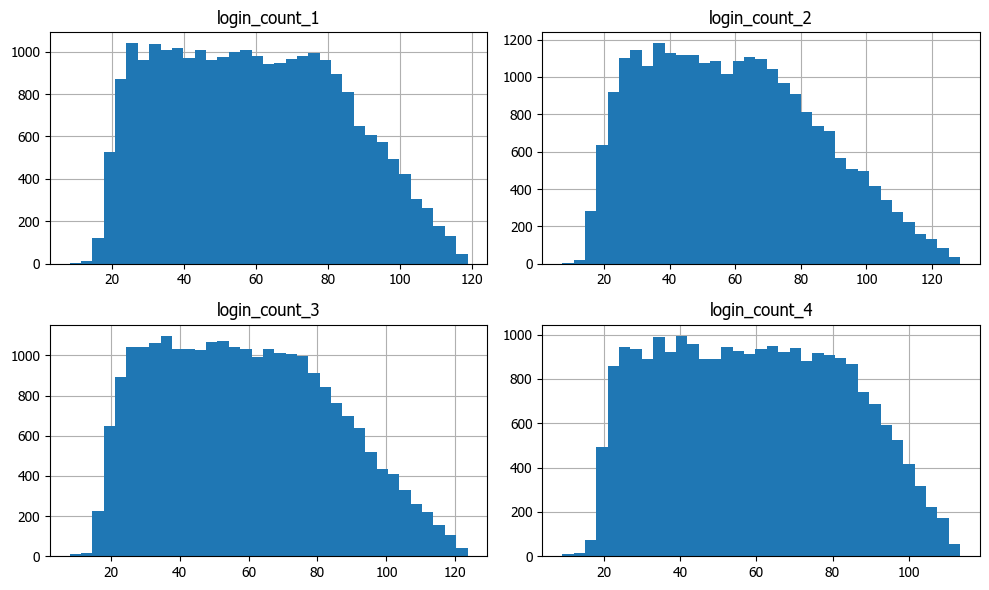

In [4]:
display(features.describe(include='all').T.head(12))
features[['login_count_1', 'login_count_2', 'login_count_3', 'login_count_4']].hist(bins=35, figsize=(10, 6))
plt.tight_layout()
plt.show()

**Findings & Interpretation**

**Findings:** ข้อมูลตัวเลขมี 122 feature; `login_count_1` median=58.086, p99=110.938; `login_count_2` median=57.268, p99=118.476; `login_count_3` median=57.694, p99=114.472; `login_count_4` median=58.584, p99=107.244

**Interpretation:** ช่วงและรูปทรงของ feature ต่างกัน จึงต้องอ่านแกนและหน่วยก่อนเปรียบเทียบ

**ML Implications:** Tree baseline ไม่ต้อง scale; หากเปลี่ยนเป็น linear/distance model ให้ scale ภายใน fold

**Recommended Action:** ตรวจ target และความสัมพันธ์กับ feature เพิ่มเพื่อเลือกการแปลงข้อมูล

## 5. Feature Relationships

In [5]:
display(strongest_pairs(features).rename('pearson_r').to_frame())
deltas = period_changes(frame)
display(deltas.sort_values('p99_abs_delta', ascending=False).head(12))
columns = [f'login_count_{period}' for period in range(1, 5)]
display(frame[columns].corr())

,,pearson_r
login_lon_1,login_lon_2,1.0000
login_lat_1,login_lat_2,0.9998
login_lon_2,login_lon_3,0.9996
login_lon_1,login_lon_3,0.9996
login_lat_1,login_lat_3,0.9980
login_lat_2,login_lat_3,0.9980
login_lon_2,login_lon_4,0.9967
login_lon_1,login_lon_4,0.9966
login_lon_3,login_lon_4,0.9962
skill_rating_1,skill_rating_3,0.9866


,paired_rows,median_delta,p95_abs_delta,p99_abs_delta
feature,,,,
skill_rating,23434,0.4170,147.7391,"1,212.0345"
purchase_amount_mean,23412,0.2092,126.2510,178.6627
purchase_amount_std,23425,-0.0144,65.0471,85.4211
skill_trajectory,23513,0.0046,3.7324,64.7222
reaction_time_mean,23425,-0.3486,38.9331,58.1492
login_lon,23459,0.0084,1.5271,54.0307
session_duration_mean,23499,-0.2753,35.6678,49.4202
login_lat,23450,0.0190,1.5405,40.2270
login_count,23394,-0.0500,19.2220,25.3582


,login_count_1,login_count_2,login_count_3,login_count_4
login_count_1,1.0000,0.8619,0.8869,0.9268
login_count_2,0.8619,1.0000,0.8390,0.8776
login_count_3,0.8869,0.8390,1.0000,0.9042
login_count_4,0.9268,0.8776,0.9042,1.0000


**Findings & Interpretation**

**Findings:** พบกลุ่ม feature วัดต่อเนื่อง 29 กลุ่ม; `skill_rating` มี p99 ของ |ช่วง4−ช่วง1| 1,212.034 ในหน่วยของตัวแปรนั้น; คู่ feature ที่มี |Pearson r| สูงสุดคือ ('login_lon_1', 'login_lon_2') r=1.0000

**Interpretation:** feature หลายช่วงของบัญชีเดียวกันมีความสัมพันธ์กัน ขนาด delta ข้ามหน่วยเปรียบเทียบตรง ๆ ไม่ได้

**ML Implications:** พิจารณา delta/std และ relative change โดยป้องกันหารศูนย์; ไม่มี label จึงหา target association ไม่ได้

**Recommended Action:** ตรวจแนวโน้มรายตัวแปรและเลือก feature summary โดยไม่เรียกแถวใดว่า anomaly จริง

### Feature interactions

In [6]:
login_delta = frame.login_count_4 - frame.login_count_1
device_delta = frame.device_count_4 - frame.device_count_1
interaction = pd.crosstab(pd.qcut(login_delta, 4, duplicates='drop'),
                          pd.qcut(device_delta, 4, duplicates='drop'))
display(interaction)

col_0,"(-0.001, 1.0]","(1.0, 2.0]"
row_0,,
"(-33.777, -5.58]",5241,55
"(-5.58, -0.05]",5237,59
"(-0.05, 5.361]",5231,66
"(5.361, 33.274]",5221,76


**Findings & Interpretation**

**Findings:** ตาราง interaction มี 4×2 ช่อง; ค่าที่สังเกตได้ต่ำสุด 55.0000, สูงสุด 5,241.0000

**Interpretation:** ตารางนับบัญชีที่มีการเปลี่ยน login และ device ร่วมกัน ไม่ใช่จำนวน anomaly ที่ยืนยันแล้ว; ช่วง bin มาจาก quartile ของข้อมูลที่ใช้วิเคราะห์ และบางช่องอาจมีตัวอย่างน้อย

**ML Implications:** Tree model รองรับความสัมพันธ์ร่วมแบบนี้ได้; ยังไม่สร้างกฎตัดสินจาก EDA เพียงอย่างเดียว

**Recommended Action:** อ่านจำนวนตัวอย่างในแต่ละช่องก่อนตีความ และตรวจผลบน validation แยกจาก EDA

## 6. Task-Specific EDA

,observed_mean
password_changed,0.0627
vpn_usage,0.1570
suspicious_login_time,0.0493
mass_item_sale,0.0273


,paired_rows,median_delta,p95_abs_delta,p99_abs_delta
feature,,,,
login_count,23394,-0.0500,19.2220,25.3582
device_count,23456,1.0000,1.0000,2.0000
purchase_amount_mean,23412,0.2092,126.2510,178.6627
skill_rating,23434,0.4170,147.7391,"1,212.0345"


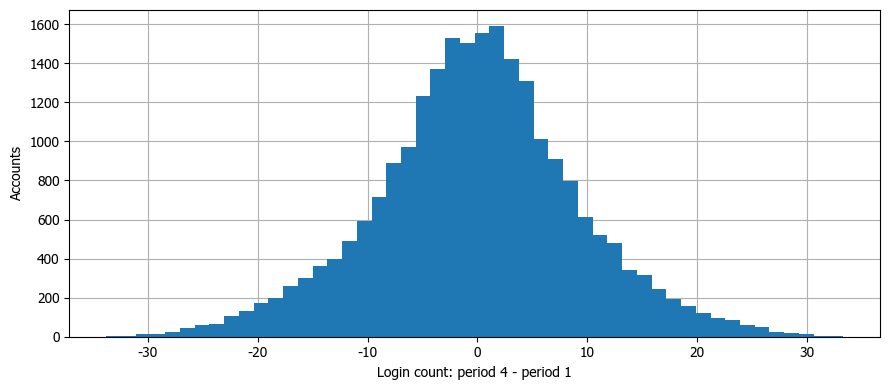

In [7]:
display(frame[['password_changed', 'vpn_usage', 'suspicious_login_time', 'mass_item_sale']].mean().to_frame('observed_mean'))
deltas = period_changes(frame)
display(deltas.loc[['login_count', 'device_count', 'purchase_amount_mean', 'skill_rating']])
delta_login = frame.login_count_4 - frame.login_count_1
delta_login.hist(bins=50)
plt.xlabel('Login count: period 4 - period 1')
plt.ylabel('Accounts')
plt.tight_layout()
plt.show()

**Findings & Interpretation**

**Findings:** Login delta median=-0.050, p99 |delta|=25.358; vpn_usage mean=0.1570 คำนวณจากค่าที่ไม่ missing

**Interpretation:** flag ที่ให้มาเป็น input ไม่ใช่ ground truth ของ is_anomaly และค่าเฉลี่ยของ flag ไม่ใช่ anomaly rate

**ML Implications:** ใช้ทั้งระดับพฤติกรรมและความเปลี่ยนแปลง; ห้ามรายงาน F1 หรือ accuracy เมื่อไม่มี label

**Recommended Action:** เริ่ม IsolationForest แล้วทดสอบความไวของ threshold ภายหลัง; ต้องขอ label เพื่อยืนยันคุณภาพ

## 7. EDA Findings & Insights

- Feature missing เฉลี่ย 4.87% และมีค่าที่อยู่นอกช่วงตรวจ 14,073 จุด
- Duplicate feature rows 0 แถว
- มีเฉพาะ test ไม่มี label จึงยังสรุปความแม่นยำของ anomaly detection ไม่ได้
- ความสัมพันธ์เป็น observed association; leakage และสาเหตุของค่าผิดช่วงยังเป็นประเด็นที่ต้องตรวจ

## 8. Preprocessing Recommendations

- ไม่ใช้ player_id เป็น predictor และไม่เติม target ที่หาย
- Fit imputer/encoder เฉพาะ training fold; HistGradientBoosting รองรับ NaN ใน numerical features
- ยังไม่ลบ IQR outlier อัตโนมัติ เพราะอาจเป็นกลุ่มพฤติกรรมที่ต้องการทำนาย
- เพิ่ม delta/std ของ 4 ช่วงเวลา; median imputation พร้อม indicator; แยก NaN จากศูนย์
- Tree model ไม่จำเป็นต้อง scale; ถ้าใช้ linear/distance model ให้ scale ภายใน fold

## 9. Baseline Model Recommendations

เริ่ม IsolationForest บนข้อมูล unlabeled พร้อม delta/std; ไม่มี supervised validation การ fit บน test เป็น transductive ต้องตรวจข้อกำหนดการแข่งขันก่อนส่ง; top 10% เป็นสมมติฐานเริ่มต้นเท่านั้น

การฝึกโมเดลอยู่ใน `02_baseline.ipynb` ไม่มีการ fit ใน EDA notebook นี้

## 10. Final EDA Summary

ยืนยันจากข้อมูลในเครื่อง: 25,889 แถวที่ใช้วิเคราะห์, 122 feature, missing เฉลี่ย 4.87% และ known labels 0 แถว

ขั้นถัดไปคือรัน baseline แยกจาก EDA ตรวจ prediction และเก็บ local validation ก่อนปรับโมเดลให้ยืนยัน metric ทางการ วิธีจับคู่แถว submission และ provenance ของ feature ยังไม่สามารถพิสูจน์ temporal leakage หรือสาเหตุที่ข้อมูลบางค่าหลุดช่วงจากไฟล์ปัจจุบันได้